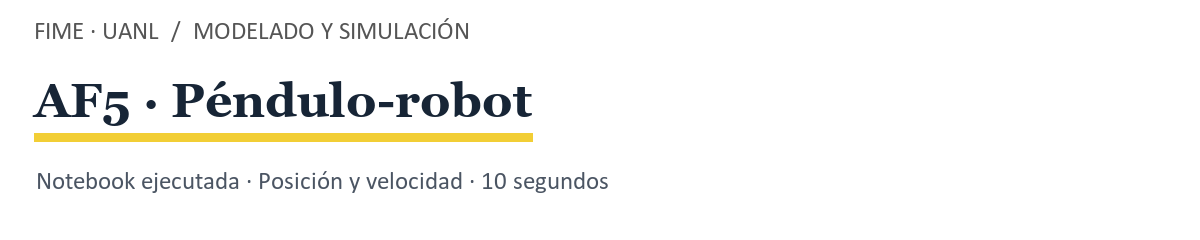

**Modelado y Simulación de Sistemas Mecatrónicos** · Grupo 004 · V6

[Documento del equipo en Prism](https://prism.openai.com/?u=1eb8506f-eb59-4978-9170-48f4db936aa4&pg=1)

**Contenido:** objetivo → diagrama → modelo → estados → simulación → resultados → conclusión → referencias.

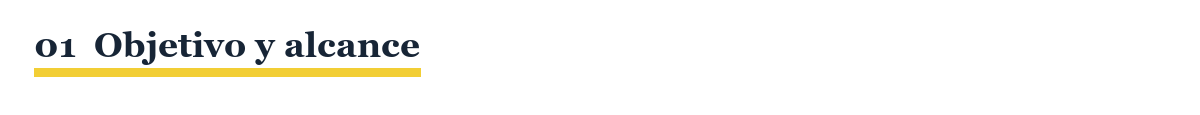

Obtener el modelo de una articulación tipo péndulo mediante Euler–Lagrange, incorporar el par motor y la fricción, y simular posición y velocidad durante **10 segundos**.

> **Pendiente del equipo:** redactar la conclusión grupal y confirmar los supuestos con lo visto en clase.

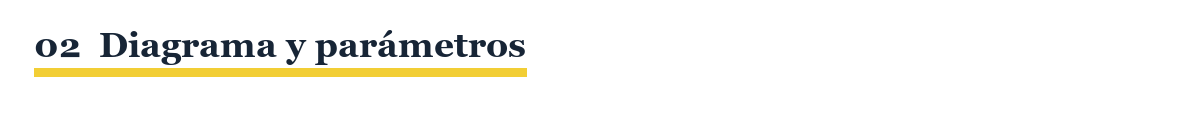

| Parámetro | Valor | Unidad |
|---|---:|---|
| Inercia articular $I_r$ | 0.16 | kg·m² |
| Masa $m$ | 5 | kg |
| Gravedad $g$ | 9.81 | m/s² |
| Distancia al centro de masa $l_c$ | 0.01 | m |
| Fricción viscosa $b$ | 0.14 | N·m·s/rad |
| Fricción de Coulomb $f_c$ | 0.45 | N·m |

**Condiciones iniciales:** $x_1(0)=0$ rad y $x_2(0)=0$ rad/s.

**Supuestos:** par constante de **1 N·m** y ángulo desde la vertical inferior. Se interpreta $I_r$ respecto de la articulación. Estos supuestos deben cotejarse con el ejemplo de clase.

**Sistema de referencia:** origen en O, eje x hacia la derecha, eje y hacia arriba y ángulo positivo antihorario desde la vertical inferior. Diagrama esquemático, no a escala.

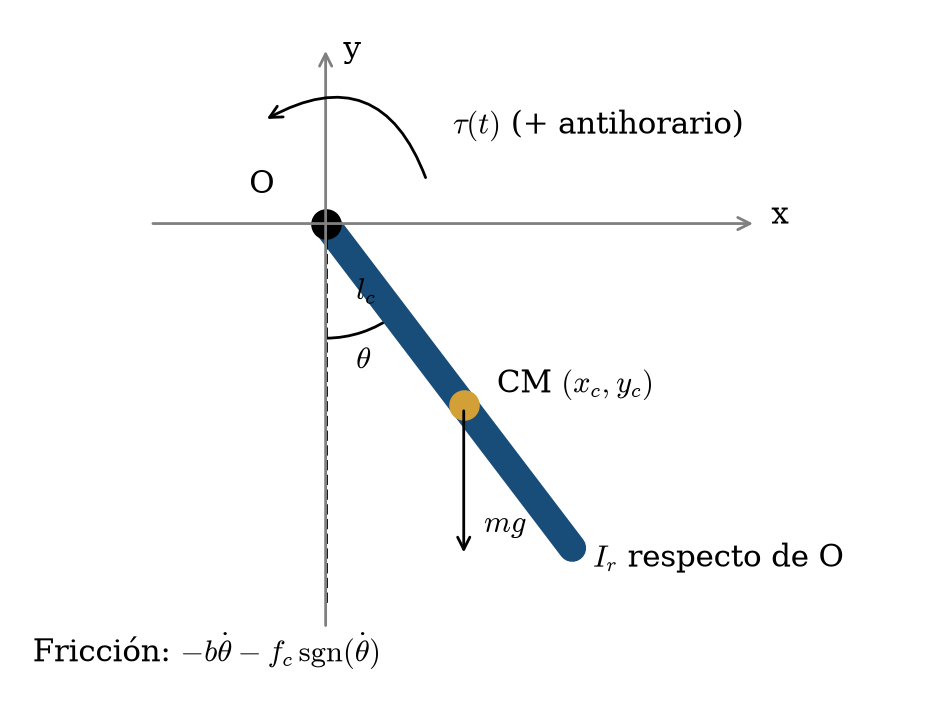

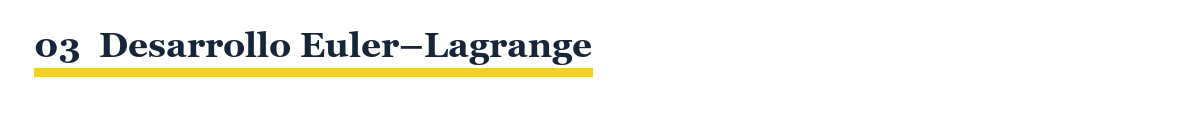

### Paso 1 · Coordenada generalizada
$$q=\theta,\qquad x_c=l_c\sin\theta,\qquad y_c=-l_c\cos\theta.$$

### Paso 2 · Energías del sistema
$$T=\frac{1}{2}I_r\dot\theta^2,\qquad V=mgl_c(1-\cos\theta).$$

### Paso 3 · Lagrangiano y par no conservativo
$$L=T-V,\qquad Q_{nc}=\tau-b\dot\theta-f_c\operatorname{sgn}(\dot\theta).$$

### Paso 4 · Euler–Lagrange
$$\frac{d}{dt}\left(\frac{\partial L}{\partial\dot\theta}\right)-\frac{\partial L}{\partial\theta}=Q_{nc}.$$
$$\frac{\partial L}{\partial\dot\theta}=I_r\dot\theta,\qquad \frac{\partial L}{\partial\theta}=-mgl_c\sin\theta.$$

### Paso 5 · Ecuación dinámica
$$I_r\ddot\theta+b\dot\theta+mgl_c\sin\theta+f_c\operatorname{sgn}(\dot\theta)=\tau(t).$$
$$0.16\ddot\theta+0.14\dot\theta+0.4905\sin\theta+0.45\operatorname{sgn}(\dot\theta)=\tau(t).$$

La fricción seca con signo describe deslizamiento. La simulación usa una regularización suave; no representa adherencia estática exacta.

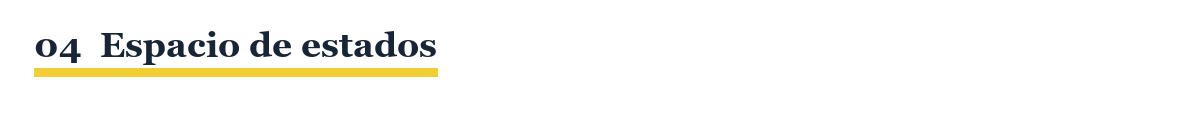

$$x_1=\theta,\qquad x_2=\dot\theta,\qquad u=\tau.$$
$$\dot x_1=x_2.$$
$$\dot x_2=\frac{u-0.14x_2-0.4905\sin x_1-0.45\operatorname{sgn}(x_2)}{0.16}.$$
Las salidas son la **posición angular** $y_1=x_1$ y la **velocidad angular** $y_2=x_2$.

**Modelo auxiliar lineal:** al omitir Coulomb y aproximar $\sin\theta\approx\theta$, el polinomio característico es $0.16s^2+0.14s+0.4905=0$. No describe el modelo no lineal completo utilizado en la simulación.

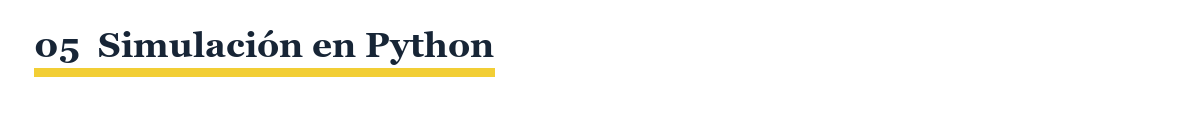

**Método:** RK45 con `solve_ivp`; 2001 instantes de salida entre 0 y 10 s. Se aproxima $\operatorname{sgn}(x_2)$ por $\tanh(x_2/\varepsilon)$ con $\varepsilon=0.001$ rad/s. Esta regularización no modela adherencia estática exacta.

### A. Parámetros y función del modelo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import scipy
Ir, m, g, lc, b, fc = 0.16, 5.0, 9.81, 0.01, 0.14, 0.45
tau0 = 1.0  # N m: supuesto de trabajo, no especificado en la consigna
eps = 0.001  # rad/s, regularizacion de Coulomb
t = np.linspace(0.0, 10.0, 2001)
x0 = [0.0, 0.0]
def torque(t):
    return tau0
def modelo(t, x, epsilon=eps):
    theta, omega = x
    return [omega, (torque(t)-b*omega-fc*np.tanh(omega/epsilon)
                    -m*g*lc*np.sin(theta))/Ir]
print('NumPy:', np.__version__, '| SciPy:', scipy.__version__)


NumPy: 2.3.5 | SciPy: 1.18.1


### B. Integración temporal

In [2]:
sol = solve_ivp(modelo, (0, 10), x0, t_eval=t, rtol=1e-9, atol=1e-11, max_step=0.01)
assert sol.success, sol.message
theta, omega = sol.y
print(f'Posicion a 10 s: {theta[-1]:.6f} rad ({np.degrees(theta[-1]):.3f} grados)')
print(f'Velocidad a 10 s: {omega[-1]:.6f} rad/s')
print(f'Velocidad maxima muestreada: {omega.max():.6f} rad/s')


Posicion a 10 s: 29.194922 rad (1672.746 grados)
Velocidad a 10 s: 3.638357 rad/s
Velocidad maxima muestreada: 4.654989 rad/s


### C. Gráficas de posición y velocidad

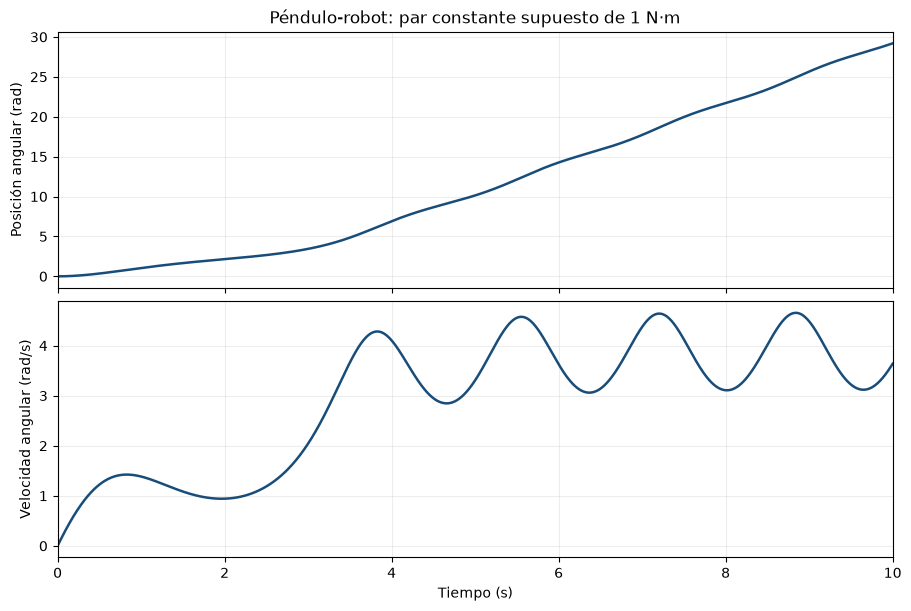

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, y, label in zip(axes, [theta, omega], ['Posición angular (rad)', 'Velocidad angular (rad/s)']):
    ax.plot(t, y, color='#184d7a', linewidth=1.8)
    ax.set_ylabel(label); ax.grid(alpha=0.22); ax.set_xlim(0,10)
axes[0].set_title('Péndulo-robot: par constante supuesto de 1 N·m')
axes[1].set_xlabel('Tiempo (s)')
plt.show()


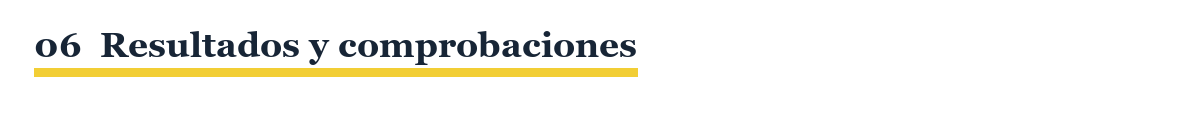

| Magnitud | Resultado |
|---|---:|
| Posición a 10 s | 29.194922 rad |
| Velocidad a 10 s | 3.638357 rad/s |
| Velocidad máxima muestreada | 4.654989 rad/s |

La posición se muestra **sin envolver a ±π**. Con el par supuesto de 1 N·m se producen rotaciones completas: el par supera la suma de Coulomb y el máximo par gravitacional, **0.9405 N·m**. No es una respuesta controlada a una posición deseada.

### Verificaciones numéricas y físicas

In [4]:
ref = solve_ivp(modelo, (0,10), x0, t_eval=t, rtol=1e-11, atol=1e-13, max_step=0.005)
error = np.max(np.abs(sol.y-ref.y),axis=1)
assert ref.success and np.all(error < 1e-5)
print('Diferencias máximas con tolerancia más estricta [rad, rad/s]:', error)
for epsilon in [0.002, 0.0005]:
    alt = solve_ivp(lambda tt,xx: modelo(tt,xx,epsilon), (0,10), x0,
                    t_eval=t, rtol=1e-9, atol=1e-11, max_step=0.01)
    assert alt.success
    print('epsilon:',epsilon,'; diferencia máxima [rad, rad/s]:', np.max(np.abs(sol.y-alt.y),axis=1))
# Comprobación independiente: trabajo del motor = energía + disipación.
from scipy.integrate import cumulative_trapezoid
energia = 0.5*Ir*omega**2 + m*g*lc*(1-np.cos(theta))
potencia = tau0*omega - b*omega**2 - fc*np.tanh(omega/eps)*omega
residuo = energia - cumulative_trapezoid(potencia,t,initial=0)
assert np.max(np.abs(residuo)) < 1e-3
print('Residuo máximo de balance energético (J):', np.max(np.abs(residuo)))
reposo = solve_ivp(lambda tt,xx: [xx[1],(-b*xx[1]-fc*np.tanh(xx[1]/eps)-m*g*lc*np.sin(xx[0]))/Ir],
                   (0,10), x0, t_eval=t)
assert np.allclose(reposo.y,0)
print('Sin par y desde el equilibrio: posición y velocidad permanecen en cero.')


Diferencias máximas con tolerancia más estricta [rad, rad/s]: [5.86197757e-12 8.48832116e-12]
epsilon: 0.002 ; diferencia máxima [rad, rad/s]: [0.0005442  0.00041443]


epsilon: 0.0005 ; diferencia máxima [rad, rad/s]: [0.00027169 0.0002069 ]
Residuo máximo de balance energético (J): 8.16337164066816e-06
Sin par y desde el equilibrio: posición y velocidad permanecen en cero.


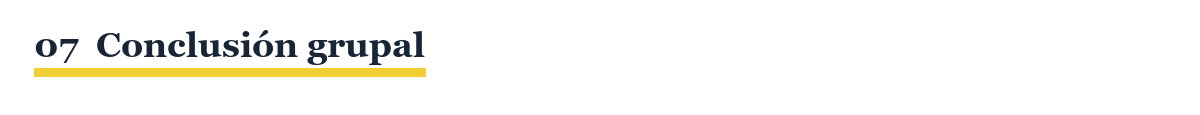

**Pendiente del equipo.** Completar la conclusión en el documento de Prism, explicando lo aprendido con Euler–Lagrange, el efecto de la fricción y del par motor, la interpretación de las gráficas y las limitaciones de los supuestos.

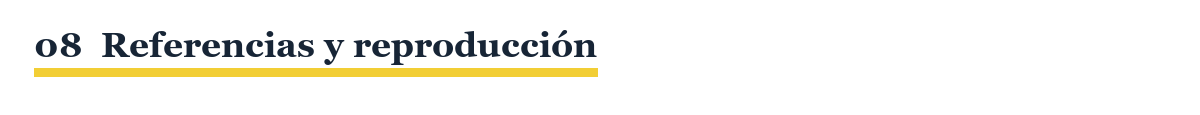

- [Tedrake, R. · Underactuated Robotics: The Simple Pendulum](https://underactuated.mit.edu/pend.html).
- [SciPy · Documentación oficial de solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).

### Cómo ejecutar
1. Instalar las dependencias: `pip install -r requirements.txt`.
2. Abrir la notebook en Jupyter o Google Colab.
3. Ejecutar todas las celdas en orden.

Las salidas y gráficas guardadas corresponden a los parámetros indicados. Las comprobaciones verifican convergencia, sensibilidad de la regularización, balance energético y reposo sin par motor.